# Tópico 2, Hands-On 2: Movimento em poços simples e duplo (CAP-422)
Objetivo: ligar a formulação lagrangiana à dinâmica numérica e à dissipação de energia.
Rode célula por célula ou tudo: `python topic02_variational/handson_2_potential_wells.py`

In [1]:
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
OUT = ROOT / "topic02_variational" / "outputs"
OUT.mkdir(exist_ok=True)

import matplotlib

if "get_ipython" not in globals():  # como script; no notebook as figuras aparecem na célula
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

from cap422.dynamics import integrate, mech_energy, well_rhs
from cap422.variational import euler_lagrange, euler_lagrange_with_rayleigh

## 2.1 Os dois potenciais
V1(x) = ½ k x²  e  V2(x) = a (x² − b²)². Escolhi m = 1, k = 1, a = 0.25, b = 1.
Pontos estacionários: V'(x) = 0. Em V1 só x = 0 (mínimo). Em V2: x = 0 (máximo, a barreira
central, V2(0) = a b⁴ = 0.25) e x = ±b (dois mínimos, V2 = 0).

2.1) Pontos estacionários (V' = 0), com k=1, a=0.25, b=1:
   V1: x = 0  -> mínimo (V'' = 1.00000000000000)
   V2: x = 0  -> máximo (V'' = -1.00000000000000)
   V2: x = -1.00000000000000  -> mínimo (V'' = 2.00000000000000)
   V2: x = 1.00000000000000  -> mínimo (V'' = 2.00000000000000)


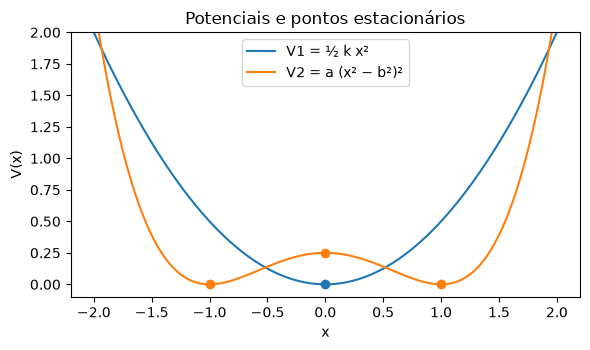

In [2]:
m_, k_, a_, b_ = 1.0, 1.0, 0.25, 1.0
xs = sp.Symbol("x", real=True)
k, a, b, m = sp.symbols("k a b m", positive=True)
V1s = sp.Rational(1, 2) * k * xs**2
V2s = a * (xs**2 - b**2) ** 2

params = {k: k_, a: a_, b: b_}
print("2.1) Pontos estacionários (V' = 0), com k=1, a=0.25, b=1:")
for nome, V in (("V1", V1s), ("V2", V2s)):
    for p in sp.solve(sp.diff(V, xs), xs):
        p_num = p.subs(params)
        curv = sp.diff(V, xs, 2).subs(xs, p).subs(params)
        tipo = "mínimo" if curv > 0 else "máximo"
        print(f"   {nome}: x = {p_num}  -> {tipo} (V'' = {curv})")

V1 = sp.lambdify(xs, V1s.subs({k: k_}), "numpy")
V2 = sp.lambdify(xs, V2s.subs({a: a_, b: b_}), "numpy")

xx = np.linspace(-2, 2, 400)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(xx, V1(xx), label="V1 = ½ k x²")
ax.plot(xx, V2(xx), label="V2 = a (x² − b²)²")
ax.scatter([0], [V1(0)], c="C0", zorder=3)
ax.scatter([-b_, 0, b_], [V2(-b_), V2(0), V2(b_)], c="C1", zorder=3)
ax.set(xlabel="x", ylabel="V(x)", ylim=(-0.1, 2), title="Potenciais e pontos estacionários")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "h2_potenciais.png", dpi=150)

## 2.2 V'(x) e a equação de Euler-Lagrange
Com L = ½ m ẋ² − V(x), a equação é m ẍ + V'(x) = 0 (a 2ª lei de Newton, F = −V').

In [3]:
t = sp.Symbol("t", real=True)
X = sp.Function("x")(t)
dV1 = sp.diff(V1s, xs)
dV2 = sp.diff(V2s, xs)
print("2.2) V1'(x) =", dV1, "| V2'(x) =", sp.expand(dV2))
for nome, V in (("V1", V1s), ("V2", V2s)):
    L = sp.Rational(1, 2) * m * sp.diff(X, t) ** 2 - V.subs(xs, X)
    print(f"   {nome}: EL ->", sp.Eq(euler_lagrange(L, X, t), 0))

# Com atrito de Rayleigh R = ½ γ ẋ²  (dissipação):
g = sp.Symbol("gamma", positive=True)
L2 = sp.Rational(1, 2) * m * sp.diff(X, t) ** 2 - V2s.subs(xs, X)
R = sp.Rational(1, 2) * g * sp.diff(X, t) ** 2
print("   V2 com Rayleigh ->", sp.Eq(euler_lagrange_with_rayleigh(L2, X, t, R), 0))

2.2) V1'(x) = k*x | V2'(x) = -4*a*b**2*x + 4*a*x**3
   V1: EL -> Eq(k*x(t) + m*Derivative(x(t), (t, 2)), 0)
   V2: EL -> Eq(-4*a*(b**2 - x(t)**2)*x(t) + m*Derivative(x(t), (t, 2)), 0)
   V2 com Rayleigh -> Eq(-4*a*(b**2 - x(t)**2)*x(t) + gamma*Derivative(x(t), t) + m*Derivative(x(t), (t, 2)), 0)


## 2.3 Sistema de 1ª ordem
Com v = ẋ:   ẋ = v,   v̇ = −(V'(x) + γ v)/m.   Integro com `scipy.integrate.solve_ivp`
(método DOP853, tolerâncias 1e-10 / 1e-12), via `cap422.dynamics.integrate`.

In [4]:
dV1n = sp.lambdify(xs, dV1.subs({k: k_}), "numpy")
dV2n = sp.lambdify(xs, dV2.subs({a: a_, b: b_}), "numpy")
pocos = {"poço simples V1": (V1, dV1n, [1.5, 0.0]), "poço duplo V2": (V2, dV2n, [1.6, 0.0])}
T_END = 40.0

## 2.4 Sem atrito (γ = 0): x(t), ẋ(t) e E_mec(t)

2.4) poço simples V1: E0 = 1.125000 | desvio relativo máximo = 4.24e-10
2.4) poço duplo V2: E0 = 0.608400 | desvio relativo máximo = 4.20e-10


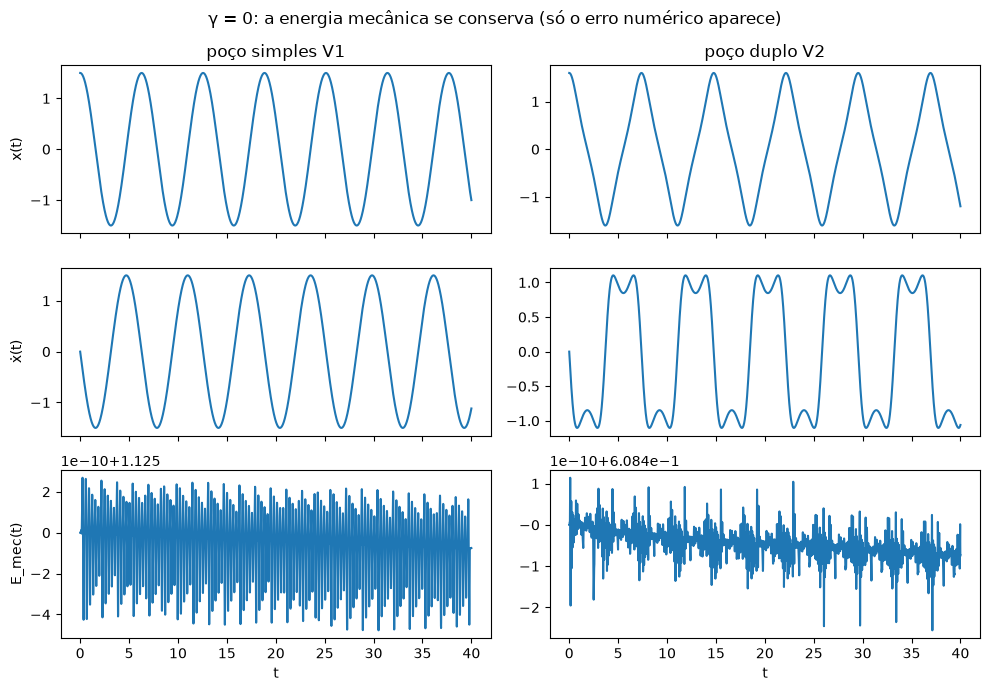

In [5]:
fig, axs = plt.subplots(3, 2, figsize=(10, 7), sharex=True)
for col, (nome, (V, dV, s0)) in enumerate(pocos.items()):
    sol = integrate(well_rhs(dV, m_, 0.0), s0, T_END)
    E = mech_energy(sol.y[0], sol.y[1], V, m_)
    deriva = np.max(np.abs(E - E[0])) / abs(E[0])
    print(f"2.4) {nome}: E0 = {E[0]:.6f} | desvio relativo máximo = {deriva:.2e}")
    axs[0, col].plot(sol.t, sol.y[0]); axs[0, col].set_title(nome)
    axs[1, col].plot(sol.t, sol.y[1])
    axs[2, col].plot(sol.t, E); axs[2, col].set_xlabel("t")
axs[0, 0].set_ylabel("x(t)"); axs[1, 0].set_ylabel("ẋ(t)"); axs[2, 0].set_ylabel("E_mec(t)")
fig.suptitle("γ = 0: a energia mecânica se conserva (só o erro numérico aparece)")
fig.tight_layout()
fig.savefig(OUT / "h2_sem_atrito.png", dpi=150)

**Leitura:** com γ = 0 a energia fica constante até ~1e-9 (relativo). O que sobra é erro do
integrador, não física. No poço duplo, a condição inicial x0 = 1.6, v0 = 0 dá E0 ≈ 0.61,
acima da barreira (V2(0) = 0.25), então a partícula passa pelo centro e vai de um lado ao outro.

## 2.5 Com atrito de Rayleigh: γ = 0.2, 0.6, 2.0
Repito os gráficos de x(t), ẋ(t) e E_mec(t), agora com atrito. Tudo é adimensional (m = 1).
Perto de um mínimo, o regime depende da razão γ / (2 √(m V'')), com V'' calculada no mínimo:

| γ | poço simples (V'' = 1) | mínimos do poço duplo (V'' = 2) |
|---|---|---|
| 0.2 | 0.10, subamortecido | 0.07, subamortecido |
| 0.6 | 0.30, subamortecido | 0.21, subamortecido |
| 2.0 | 1.00, crítico | 0.71, subamortecido |

2.5) poço simples V1: γ / (2 √(m V'')) = 0.10, 0.30, 1.00
2.5) poço simples V1, γ = 0.2: x(40) = -0.0115, E(40) = 3.50e-04
2.5) poço simples V1, γ = 0.6: x(40) = +0.0000, E(40) = 5.47e-11
2.5) poço simples V1, γ = 2.0: x(40) = +0.0000, E(40) = 3.59e-32
2.5) poço duplo V2: γ / (2 √(m V'')) = 0.07, 0.21, 0.71
2.5) poço duplo V2, γ = 0.2: x(40) = -0.9927, E(40) = 2.13e-04
2.5) poço duplo V2, γ = 0.6: x(40) = +1.0000, E(40) = 4.02e-11
2.5) poço duplo V2, γ = 2.0: x(40) = +1.0000, E(40) = 5.05e-28


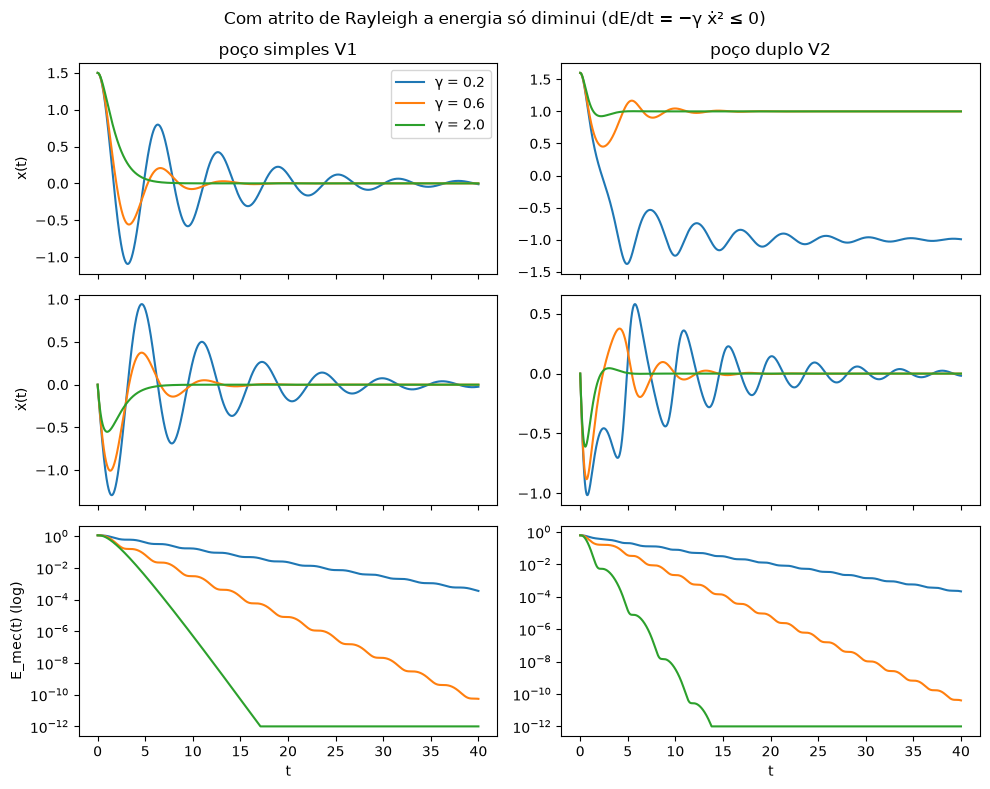

In [6]:
gammas = (0.2, 0.6, 2.0)
curvaturas = {"poço simples V1": k_, "poço duplo V2": 8 * a_ * b_**2}  # V'' no mínimo
fig, axs = plt.subplots(3, 2, figsize=(10, 8), sharex=True)
for col, (nome, (V, dV, s0)) in enumerate(pocos.items()):
    razoes = ", ".join(f"{gm / (2 * np.sqrt(m_ * curvaturas[nome])):.2f}" for gm in gammas)
    print(f"2.5) {nome}: γ / (2 √(m V'')) = {razoes}")
    for gm in gammas:
        sol = integrate(well_rhs(dV, m_, gm), s0, T_END)
        E = mech_energy(sol.y[0], sol.y[1], V, m_)
        axs[0, col].plot(sol.t, sol.y[0], label=f"γ = {gm}")
        axs[1, col].plot(sol.t, sol.y[1])
        axs[2, col].semilogy(sol.t, np.maximum(E, 1e-12))
        print(f"2.5) {nome}, γ = {gm}: x(40) = {sol.y[0][-1]:+.4f}, E(40) = {E[-1]:.2e}")
    axs[0, col].set_title(nome); axs[2, col].set_xlabel("t")
axs[0, 0].set_ylabel("x(t)"); axs[1, 0].set_ylabel("ẋ(t)"); axs[2, 0].set_ylabel("E_mec(t) (log)")
axs[0, 0].legend()
fig.suptitle("Com atrito de Rayleigh a energia só diminui (dE/dt = −γ ẋ² ≤ 0)")
fig.tight_layout()
fig.savefig(OUT / "h2_com_atrito.png", dpi=150)

**Leitura:** a energia só diminui, e quanto maior γ, mais depressa o movimento morre nos primeiros
ciclos. No poço duplo, partindo de x0 = 1.6 em repouso, com γ = 0.2 a partícula cruza a barreira e
termina no mínimo x = −1; com γ = 0.6 e γ = 2.0 ela perde energia antes e fica em x = +1. Os
"degraus" na curva de energia aparecem onde ẋ = 0, pois ali não há dissipação. Na escala log, a
energia desenhada foi limitada por baixo em 1e-12.

## 2.6 Poço duplo: quando cruza a barreira e para qual mínimo vai
Varro uma grade de condições iniciais (x0, v0). Sem atrito, a partícula cruza x = 0 quando
E0 = ½ v0² + V2(x0) > V2(0) = 0.25 (a curva tracejada). Com γ = 0.2, ela pode cruzar algumas vezes
e acaba presa em um dos dois mínimos, x = −1 ou x = +1.
"Cruzar" aqui é trocar o sinal de x; apenas partir de x0 = 0 não conta.

2.6) γ = 0: critério E0 > V2(0) acerta em 100.0% das condições iniciais
2.6) γ = 0.2: 1420 condições com E0 > V2(0); 1218 cruzaram (85.8%) e 202 não; sem essa energia cruzaram 0


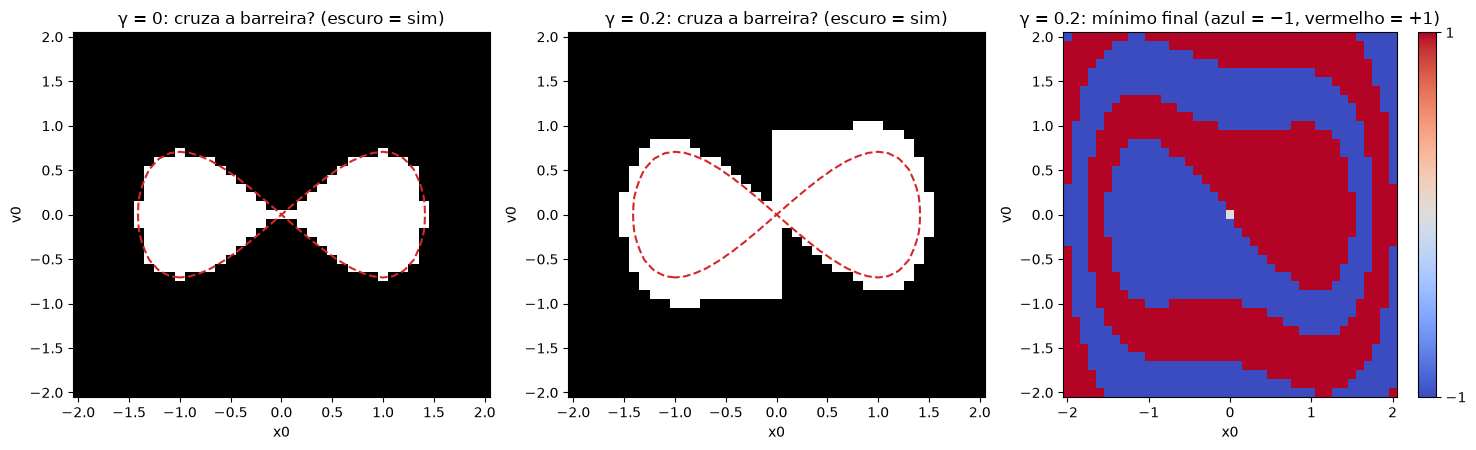

In [7]:
def varrer(gm, n=41, t_end=60.0):
    x0s = np.linspace(-2, 2, n)
    v0s = np.linspace(-2, 2, n)
    cruzou = np.zeros((n, n), dtype=bool)
    final = np.zeros((n, n))
    for i, v0 in enumerate(v0s):
        for j, x00 in enumerate(x0s):
            sol = integrate(well_rhs(dV2n, m_, gm), [x00, v0], t_end, n=600)
            xt = sol.y[0]
            cruzou[i, j] = bool(np.any(xt[1:] * xt[:-1] < 0))  # troca estrita de sinal
            final[i, j] = np.sign(xt[-1])
    return x0s, v0s, cruzou, final

x0s, v0s, cruz0, _ = varrer(0.0)
_, _, cruz1, final1 = varrer(0.2)

X0, V0 = np.meshgrid(x0s, v0s)
E0 = mech_energy(X0, V0, V2, m_)
concorda = np.mean(cruz0 == (E0 > V2(0.0)))
print(f"2.6) γ = 0: critério E0 > V2(0) acerta em {100 * concorda:.1f}% das condições iniciais")

com_energia = E0 > V2(0.0)
n_com, n_cruz = com_energia.sum(), (cruz1 & com_energia).sum()
print(f"2.6) γ = 0.2: {n_com} condições com E0 > V2(0); {n_cruz} cruzaram ({100 * n_cruz / n_com:.1f}%) "
      f"e {n_com - n_cruz} não; sem essa energia cruzaram {(cruz1 & ~com_energia).sum()}")

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, mapa, gm in ((axs[0], cruz0, 0), (axs[1], cruz1, 0.2)):
    ax.pcolormesh(X0, V0, mapa, shading="auto", cmap="Greys")
    ax.contour(X0, V0, E0, levels=[V2(0.0)], colors="C3", linestyles="--")
    ax.set(title=f"γ = {gm}: cruza a barreira? (escuro = sim)", xlabel="x0", ylabel="v0")
im = axs[2].pcolormesh(X0, V0, final1, shading="auto", cmap="coolwarm")
axs[2].set(title="γ = 0.2: mínimo final (azul = −1, vermelho = +1)", xlabel="x0", ylabel="v0")
fig.colorbar(im, ax=axs[2], ticks=[-1, 1])
fig.tight_layout()
fig.savefig(OUT / "h2_barreira.png", dpi=150)

**Leitura:**
- **Sem atrito**, o critério de energia explica o mapa inteiro (na grade usada, acerta em todos os pontos).
- **Com atrito**, ter E0 > V2(0) passa a ser necessário, mas não suficiente: parte das condições com essa
  energia perde o excesso antes de conseguir passar pelo topo da barreira. Nenhuma condição sem essa
  energia cruza.
- **Mínimo final:** o mapa vira faixas curvas alternando azul e vermelho. Perto das fronteiras, uma mudança
  pequena na condição inicial troca o destino. Isso não é caos: cada trajetória é regular e termina em
  repouso; o que é intrincado é a fronteira entre as duas bacias de atração.
- O ponto x0 = v0 = 0 fica parado no topo da barreira, um equilíbrio instável.

## 2.7 Mínimo de V não é mínimo da ação
Um mínimo local de V é um ponto de equilíbrio estável: ali a força é nula e qualquer pequeno
desvio gera uma força de retorno. Já a ação S[x] = ∫ (T − V) dt é um funcional sobre *caminhos*,
e o princípio de Hamilton só garante que S é **estacionária** (δS = 0) na trajetória real.
Estacionária não quer dizer mínima: pode ser mínimo, máximo ou ponto de sela.
Além disso, a ação envolve T e V juntos e depende do intervalo de tempo. No oscilador harmônico,
por exemplo, a trajetória real minimiza S só enquanto o intervalo for menor que meio período
(π/ω); passando disso, ela continua estacionária mas deixa de ser mínimo.